# Лабораторна робота 3 — Крок 6: довірчий розрахунок метрик справедливості

Захищена ознака — **`CityTier`**, привілейована група — **Tier 1**. Метрика-пріоритет за ЛР1 — **EOR**, DPR — довідково.
Прогнози — зовнішні тестові фолди вкладеної CV (`lab3_robust_validation.ipynb`). Кожен клієнт train отримав рівно один прогноз
від моделі, яка його не бачила. Результат — середнє ± std за 5 фолдами (REFORMS 7b).


In [1]:
import sys, os, json, subprocess, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, f1_score

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
REPORTS = ROOT / "reports"
ACCENT, SECOND, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d0cfca", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "legend.frameon": False,
})
from src.data import load_data_config, read_processed, read_bytes
from src.prepare_data import load_hermetic_config
from src.evaluation import load_yaml
dc, hc, costs = load_data_config(), load_hermetic_config(), load_yaml("config/costs.yaml")
CONFIG = {"LR": "config/generated/config_lr_hermetic.yaml", "RF": "config/generated/config_rf_hermetic.yaml"}

In [2]:
from src.evaluation import fairness_report
train = read_processed("train")                       # групи — з того самого DVC-знімка
X, y = train.drop(columns=[dc["target"]]), train[dc["target"]].astype(int)
final = json.loads((REPORTS / "lab3_final_model.json").read_text(encoding="utf-8"))
M = final["model"]
nested = {m: pd.read_csv(REPORTS / f"lab3_nested_{m}_predictions.csv") for m in ("LR", "RF")}
for m, P in nested.items():
    P["CityTier"] = X.loc[P.row, "CityTier"].to_numpy(); P["Gender"] = X.loc[P.row, "Gender"].to_numpy()
print("Фінальна модель (ЛР3):", M)

Фінальна модель (ЛР3):

RF

In [3]:
VARIANTS = {
    "без SMOTE, поріг 0.5": ("p_no_resample", None),
    "SMOTE, без зважування, поріг 0.5": ("p_baseline", None),
    "SMOTE + class_weight, поріг 0.5": ("p_weighted", None),
    "SMOTE + class_weight + поріг T (фінальний)": ("p_weighted", "T_weighted"),
}
def fold_fairness(P, attr="CityTier", privileged=1):
    rows = []
    for name, (pcol, tcol) in VARIANTS.items():
        for f, g in P.groupby("fold"):
            t = 0.5 if tcol is None else g[tcol].iloc[0]
            rep = fairness_report(g.y, (g[pcol] >= t).astype(int), g[attr], privileged=privileged)
            rep.insert(0, "fold", f); rep.insert(0, "variant", name)
            rows.append(rep)
    return pd.concat(rows, ignore_index=True)

fair = {m: fold_fairness(P) for m, P in nested.items()}
def agg(fr):
    out = fr[fr.group != 1].groupby(["variant", "group"], sort=False)[["selection_rate", "TPR", "DPR", "EOR"]].agg(["mean", "std"])
    return out.round(3)
trusted = agg(fair[M])
trusted.to_csv(REPORTS / f"lab3_fairness_{M}.csv")
trusted

selection_rate           TPR           DPR           EOR       
                                                           mean    std   mean    std   mean    std   mean    std
variant                                    group                                                                
без SMOTE, поріг 0.5                       2              0.086  0.061  0.524  0.281  0.858  0.705  0.938  0.415
                                           3              0.128  0.013  0.483  0.074  1.197  0.167  0.887  0.160
SMOTE, без зважування, поріг 0.5           2              0.116  0.098  0.624  0.301  0.836  0.843  0.960  0.484
                                           3              0.180  0.023  0.595  0.060  1.195  0.189  0.901  0.056
SMOTE + class_weight, поріг 0.5            2              0.159  0.109  0.827  0.205  0.789  0.592  1.062  0.284
                                           3              0.240  0.037  0.751  0.074  1.168  0.125  0.961  0.051
SMOTE + class_weight + поріг T (фінальний) 2              0.159  0.109  0.827  0.205  0.732  0.510  1.048  0.260
                                           3              0.256  0.033  0.788  0.096  1.177  0.156  1.000  0.094

## 1. Довірчий розрахунок — фінальний підхід


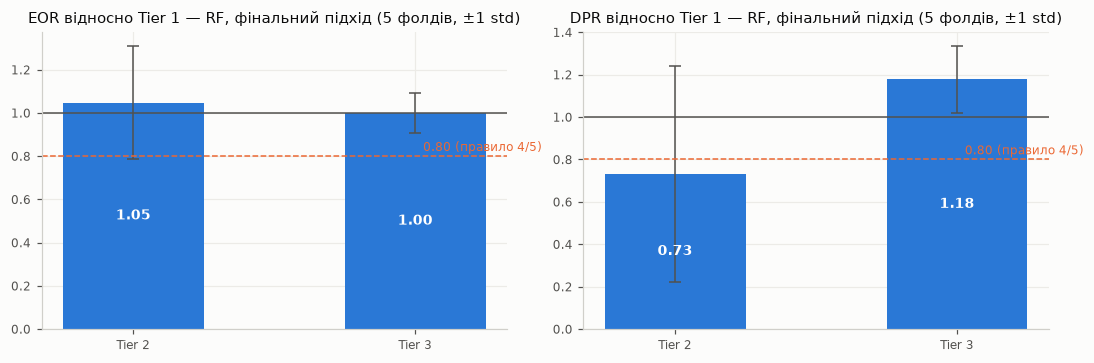

In [4]:
fin = fair[M][fair[M].variant == "SMOTE + class_weight + поріг T (фінальний)"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=False)
for ax, metric in zip(axes, ["EOR", "DPR"]):
    d = fin[fin.group != 1].groupby("group")[metric].agg(["mean", "std"])
    bars = ax.bar([f"Tier {g}" for g in d.index], d["mean"], yerr=d["std"], color=ACCENT, width=0.5,
                  error_kw=dict(ecolor=MUTED, capsize=4, linewidth=1))
    for b, v in zip(bars, d["mean"]):
        ax.text(b.get_x() + b.get_width() / 2, v / 2, f"{v:.2f}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    ax.axhline(1.0, color=MUTED, linewidth=1); ax.axhline(0.8, color=SECOND, linestyle="--", linewidth=1)
    ax.text(1.45, 0.81, "0.80 (правило 4/5)", fontsize=8, color=SECOND, ha="right", va="bottom")
    ax.set_title(f"{metric} відносно Tier 1 — {M}, фінальний підхід (5 фолдів, ±1 std)")
fig.tight_layout(); fig.savefig(REPORTS / "lab3_fairness_final.png", bbox_inches="tight"); plt.show()

## 2. Порівняння з ненадійним значенням ЛР2


In [5]:
lab2 = pd.read_csv(REPORTS / "lab2_fairness_citytier.csv")
lab2_m = lab2[(lab2.model == M) & (lab2.group != 1)][["experiment", "group", "DPR", "EOR"]]
lab3_m = fin[fin.group != 1].groupby("group")[["DPR", "EOR"]].agg(["mean", "std"])
cmp_rows = []
for g in (2, 3):
    for _, r in lab2_m[lab2_m.group == g].iterrows():
        cmp_rows.append({"group": f"Tier {g}", "джерело": f"ЛР2 · {r.experiment} (одне розбиття, поріг 0.5)", "DPR": r.DPR, "EOR": r.EOR})
    cmp_rows.append({"group": f"Tier {g}", "джерело": "ЛР3 · герметично, вкладена CV, фінальний підхід (mean ± std)",
                     "DPR": f"{lab3_m.loc[g, ('DPR', 'mean')]:.3f} ± {lab3_m.loc[g, ('DPR', 'std')]:.3f}",
                     "EOR": f"{lab3_m.loc[g, ('EOR', 'mean')]:.3f} ± {lab3_m.loc[g, ('EOR', 'std')]:.3f}"})
comparison = pd.DataFrame(cmp_rows)
comparison.to_csv(REPORTS / "lab3_fairness_vs_lab2.csv", index=False)
comparison

,group,джерело,DPR,EOR
0,Tier 2,"ЛР2 · 1. Baseline (одне розбиття, поріг 0.5)",1.118,0.707
1,Tier 2,"ЛР2 · 4. Leaky Pipeline (одне розбиття, поріг 0.5)",1.079,0.693
2,Tier 2,"ЛР3 · герметично, вкладена CV, фінальний підхід (mean ± std)",0.732 ± 0.510,1.048 ± 0.260
3,Tier 3,"ЛР2 · 1. Baseline (одне розбиття, поріг 0.5)",1.585,1.045
4,Tier 3,"ЛР2 · 4. Leaky Pipeline (одне розбиття, поріг 0.5)",1.442,1.01
5,Tier 3,"ЛР3 · герметично, вкладена CV, фінальний підхід (mean ± std)",1.177 ± 0.156,1.000 ± 0.094


## 3. До і після cost-sensitive зважування (і порогу)

In [6]:
w = fair[M][fair[M].group != 1].groupby(["group", "variant"], sort=False)[["selection_rate", "DPR", "EOR"]].mean().round(3)
w = w.loc[(slice(None), ["SMOTE, без зважування, поріг 0.5", "SMOTE + class_weight, поріг 0.5", "SMOTE + class_weight + поріг T (фінальний)"]), :]
w

,,selection_rate,DPR,EOR
group,variant,,,
2,"SMOTE, без зважування, поріг 0.5",0.116,0.836,0.960
3,"SMOTE, без зважування, поріг 0.5",0.180,1.195,0.901
2,"SMOTE + class_weight, поріг 0.5",0.159,0.789,1.062
3,"SMOTE + class_weight, поріг 0.5",0.240,1.168,0.961
2,SMOTE + class_weight + поріг T (фінальний),0.159,0.732,1.048
3,SMOTE + class_weight + поріг T (фінальний),0.256,1.177,1.000


In [7]:
conflict = fin[(fin.group != 1)].groupby("group")["DPR"].mean()
print("Середній DPR фінального підходу:", conflict.round(3).to_dict())
print("Конфлікт «бізнес-оптимум vs поріг справедливості» (DPR < 0.8):", bool((conflict < 0.8).any()))
eor = fin[(fin.group != 1)].groupby("group")["EOR"].agg(["mean", "min"])
print("EOR фінального підходу: середнє", eor["mean"].round(3).to_dict(), "| найгірший фолд", eor["min"].round(3).to_dict())

Середній DPR фінального підходу:

{2: 0.732, 3: 1.177}

Конфлікт «бізнес-оптимум vs поріг справедливості» (DPR < 0.8):

True

EOR фінального підходу: середнє

{2: 1.048, 3: 1.0}

| найгірший фолд

{2: 0.696, 3: 0.879}

## 4. Бонус: вплив ланки SMOTE

### 4a. Розподіл захищеної ознаки серед міноритарного класу до і після SMOTE (п. 4.3)

Синтетичні рядки SMOTE не мають `CityTier`: ознака виключена з `features` ще з ЛР1. Тому кожен синтетичний приклад
приписуємо групі **найближчого реального прикладу міноритарного класу** в просторі ознак моделі (1-NN). Це наближення до «батька»
інтерполяції. Розрахунок — у кожному зовнішньому фолді, на його тренувальній частині, з k, обраним Optuna для цього фолду.


In [8]:
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from joblib import Memory
from src.evaluation import build_hermetic_pipeline
memory = Memory(str(ROOT / hc["cache_dir"]), verbose=0)
folds_meta = json.loads((REPORTS / f"lab3_nested_{M}_folds.json").read_text(encoding="utf-8"))
ocv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for (f, (tr, _)), meta in zip(enumerate(ocv.split(X, y)), folds_meta):
    params = dict(meta["best_params"]); k = params.pop("k_neighbors", None)
    pipe = build_hermetic_pipeline(CONFIG[M], M, hc, model_params=params, k_neighbors=k, memory=memory).fit(X.iloc[tr], y.iloc[tr])
    Z = pipe[:-2].transform(X.iloc[tr]); yt = y.iloc[tr].to_numpy(); tier = X.iloc[tr]["CityTier"].to_numpy()
    Zr, yr = pipe.named_steps["resample"].fit_resample(Z, yt)
    synth = Zr[len(Z):]
    minority = np.flatnonzero(yt == 1)
    nn = NearestNeighbors(n_neighbors=1).fit(Z[minority])
    parent_tier = tier[minority][nn.kneighbors(synth, return_distance=False).ravel()]
    before = pd.Series(tier[minority]).value_counts(normalize=True)
    after = pd.Series(np.concatenate([tier[minority], parent_tier])).value_counts(normalize=True)
    for g in (1, 2, 3):
        rows.append({"fold": f, "group": f"Tier {g}", "частка в міноритарному класі ДО": before.get(g, 0),
                     "частка серед синтетичних": pd.Series(parent_tier).value_counts(normalize=True).get(g, 0),
                     "частка в міноритарному класі ПІСЛЯ": after.get(g, 0)})
smote_shift = pd.DataFrame(rows)
smote_tbl = smote_shift.groupby("group").agg(["mean", "std"]).drop(columns="fold").round(3)
smote_tbl.to_csv(REPORTS / "lab3_smote_group_shift.csv")
smote_tbl

частка в міноритарному класі ДО        частка серед синтетичних        частка в міноритарному класі ПІСЛЯ       
                                  mean    std                     mean    std                               mean    std
group                                                                                                                  
Tier 1                            0.55  0.007                    0.547  0.020                              0.548  0.014
Tier 2                            0.04  0.005                    0.047  0.010                              0.044  0.007
Tier 3                            0.41  0.004                    0.406  0.016                              0.407  0.009

### 4b. Метрики справедливості без SMOTE і з SMOTE (той самий поріг 0.5, без ваг)


In [9]:
s = fair[M][fair[M].group != 1].groupby(["group", "variant"], sort=False)[["selection_rate", "TPR", "DPR", "EOR"]].mean().round(3)
s.loc[(slice(None), ["без SMOTE, поріг 0.5", "SMOTE, без зважування, поріг 0.5"]), :]

,,selection_rate,TPR,DPR,EOR
group,variant,,,,
2,"без SMOTE, поріг 0.5",0.086,0.524,0.858,0.938
3,"без SMOTE, поріг 0.5",0.128,0.483,1.197,0.887
2,"SMOTE, без зважування, поріг 0.5",0.116,0.624,0.836,0.960
3,"SMOTE, без зважування, поріг 0.5",0.180,0.595,1.195,0.901


## 5. Довідково: друга захищена ознака (Gender) та друга модель


In [10]:
fg = fold_fairness(nested[M], attr="Gender", privileged="Male")
fg[(fg.group != "Male") & (fg.variant == "SMOTE + class_weight + поріг T (фінальний)")][["DPR", "EOR"]].agg(["mean", "std"]).round(3)

,DPR,EOR
mean,0.832,1.013
std,0.075,0.113


In [11]:
other = [m for m in nested if m != M][0]
agg(fair[other]).loc[["SMOTE + class_weight + поріг T (фінальний)"]]

selection_rate           TPR           DPR           EOR       
                                                           mean    std   mean    std   mean    std   mean    std
variant                                    group                                                                
SMOTE + class_weight + поріг T (фінальний) 2              0.102  0.069  0.642  0.257  0.595  0.469  0.937  0.406
                                           3              0.225  0.021  0.645  0.036  1.262  0.119  0.931  0.088